In [1]:
import glob
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
from scipy import stats

import numpy as np
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def load_data(path):
    ens = []
    ds = []
    for p in glob.glob(path):
        ens.append(p.split('/')[-1].split('_')[4])
        ds.append(xr.open_dataset(p))
    data = xr.concat(ds, dim='ens')
    data['ens'] = ens

    return data


In [2]:
enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])
enso_nao_flags_new = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_change.csv')
enso_nao_flags_new = enso_nao_flags_new.set_index(['model', 'realization'])

In [49]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
path_piControl = "/sto4/data/Intermediate/VolMIP/piControl/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L'] # , 'UKESM1-0-LL']
# colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen'] # , 'deepskyblue']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/PAPER/'
precentage = 0.75
sign= precentage * len(models)

In [50]:
lat =[-87.863799, -85.096527, -82.312913, -79.525607, -76.7369  , -73.947515,
       -71.157752, -68.367756, -65.577607, -62.787352, -59.99702 , -57.206632,
       -54.4162  , -51.625734, -48.835241, -46.044727, -43.254195, -40.463648,
       -37.67309 , -34.882521, -32.091944, -29.30136 , -26.510769, -23.720174,
       -20.929574, -18.138971, -15.348365, -12.557756,  -9.767146,  -6.976534,
        -4.185921,  -1.395307,   1.395307,   4.185921,   6.976534,   9.767146,
        12.557756,  15.348365,  18.138971,  20.929574,  23.720174,  26.510769,
        29.30136 ,  32.091944,  34.882521,  37.67309 ,  40.463648,  43.254195,
        46.044727,  48.835241,  51.625734,  54.4162  ,  57.206632,  59.99702 ,
        62.787352,  65.577607,  68.367756,  71.157752,  73.947515,  76.7369  ,
        79.525607,  82.312913,  85.096527,  87.863799]
lon = [  0.    ,   2.8125,   5.625 ,   8.4375,  11.25  ,  14.0625,  16.875 ,
        19.6875,  22.5   ,  25.3125,  28.125 ,  30.9375,  33.75  ,  36.5625,
        39.375 ,  42.1875,  45.    ,  47.8125,  50.625 ,  53.4375,  56.25  ,
        59.0625,  61.875 ,  64.6875,  67.5   ,  70.3125,  73.125 ,  75.9375,
        78.75  ,  81.5625,  84.375 ,  87.1875,  90.    ,  92.8125,  95.625 ,
        98.4375, 101.25  , 104.0625, 106.875 , 109.6875, 112.5   , 115.3125,
       118.125 , 120.9375, 123.75  , 126.5625, 129.375 , 132.1875, 135.    ,
       137.8125, 140.625 , 143.4375, 146.25  , 149.0625, 151.875 , 154.6875,
       157.5   , 160.3125, 163.125 , 165.9375, 168.75  , 171.5625, 174.375 ,
       177.1875, 180.    , 182.8125, 185.625 , 188.4375, 191.25  , 194.0625,
       196.875 , 199.6875, 202.5   , 205.3125, 208.125 , 210.9375, 213.75  ,
       216.5625, 219.375 , 222.1875, 225.    , 227.8125, 230.625 , 233.4375,
       236.25  , 239.0625, 241.875 , 244.6875, 247.5   , 250.3125, 253.125 ,
       255.9375, 258.75  , 261.5625, 264.375 , 267.1875, 270.    , 272.8125,
       275.625 , 278.4375, 281.25  , 284.0625, 286.875 , 289.6875, 292.5   ,
       295.3125, 298.125 , 300.9375, 303.75  , 306.5625, 309.375 , 312.1875,
       315.    , 317.8125, 320.625 , 323.4375, 326.25  , 329.0625, 331.875 ,
       334.6875, 337.5   , 340.3125, 343.125 , 345.9375, 348.75  , 351.5625,
       354.375 , 357.1875]

In [51]:
dict_picontrolp = {}
dict_picontroln = {}
dict_picontrolneu = {}

dict_volcp = {}
dict_volcn = {}
dict_volcneu = {}

mean_picontrolp = []
mean_picontroln = []
mean_picontrolneu = []

meanvolcp = []
meanvolcn = []
meanvolcneu = []

for i, model in enumerate(models):
    picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
    picontrol['time'] = pd.date_range(str(picontrol.time[0].values).split('-')[0], str(int(str(picontrol.time[-1].values).split('-')[0]) +1), freq='YS-FEB',unit='s')

    dict_picontrolp[model] = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    dict_picontroln[model] = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==-1).dropna().loc[model]['year'].values, method='nearest').squeeze()
    dict_picontrolneu[model] = picontrol.sel(time=enso_nao_flags.where(enso_nao_flags.nao_flag==0).dropna().loc[model]['year'].values, method='nearest').squeeze()

    volc = load_data(path + model + '/tas_Amon_*fixed_dates.nc').squeeze()
    dict_volcp[model] = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    dict_volcn[model] = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==-1)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()
    dict_volcneu[model] = volc.sel(ens=enso_nao_flags_new.where((enso_nao_flags_new.experiment=='volc') & (enso_nao_flags_new.nao_flag==0)).dropna().loc[model].index, time=slice('1991-12','1992-02')).mean('time').squeeze()

    mean_picontrolp.append(dict_picontrolp[model].interp(lat=lat, lon=lon).tas.mean('time'))
    mean_picontroln.append(dict_picontroln[model].interp(lat=lat, lon=lon).tas.mean('time'))
    mean_picontrolneu.append(dict_picontrolneu[model].interp(lat=lat, lon=lon).tas.mean('time'))

    meanvolcp.append(dict_volcp[model].interp(lat=lat, lon=lon).tas.mean('ens'))
    meanvolcn.append(dict_volcn[model].interp(lat=lat, lon=lon).tas.mean('ens'))
    meanvolcneu.append(dict_volcneu[model].interp(lat=lat, lon=lon).tas.mean('ens'))

mean_picontroln = xr.concat(mean_picontroln, dim='model')#.mean('model')
mean_picontrolp = xr.concat(mean_picontrolp, dim='model')#.mean('model')
mean_picontrolneu = xr.concat(mean_picontrolneu, dim='model')#.mean('model')

meanvolcp = xr.concat(meanvolcp, dim='model')#.mean('model')
meanvolcn = xr.concat(meanvolcn, dim='model')#.mean('model')
meanvolcneu = xr.concat(meanvolcneu, dim='model')#.mean('model')

/tmp/ipykernel_526221/4278898896.py:18: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_526221/4278898896.py:18: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  picontrol =  calculate_djf_mean(xr.open_dataset(glob.glob(path_piControl + model + '/tas_Amon_' + model + '_*.nc')[0]))
/tmp/ipykernel_526221/3886317160.py:22: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetim

In [54]:
def get_sign(data1, data2):
    data_sign = np.sign(data1 - data2)
    mean_sign = np.sign((data1 - data2).mean('model'))
    return (data_sign == mean_sign).sum('model')

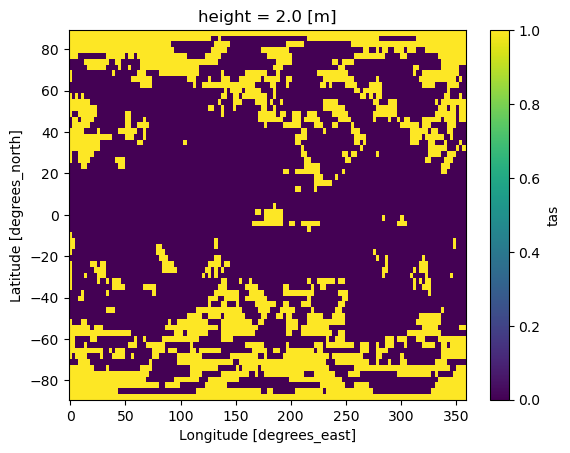

In [95]:
(get_sign(meanvolcp, mean_picontrolp) < sign).plot()

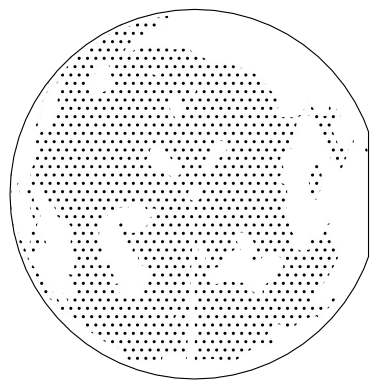

In [97]:
plt.subplots(1,1,subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)})
plt.contourf(meanvolcp.lon, meanvolcp.lat, get_sign(meanvolcp, mean_picontrolp), [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree())

In [ ]:
lon, lat = np.meshgrid(meanvolcneu.lon, meanvolcneu.lat)

(array([[  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875],
        [  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875],
        [  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875],
        ...,
        [  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875],
        [  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875],
        [  0.    ,   2.8125,   5.625 , ..., 351.5625, 354.375 , 357.1875]],
       shape=(64, 128)),
 array([[-87.863799, -87.863799, -87.863799, ..., -87.863799, -87.863799,
         -87.863799],
        [-85.096527, -85.096527, -85.096527, ..., -85.096527, -85.096527,
         -85.096527],
        [-82.312913, -82.312913, -82.312913, ..., -82.312913, -82.312913,
         -82.312913],
        ...,
        [ 82.312913,  82.312913,  82.312913, ...,  82.312913,  82.312913,
          82.312913],
        [ 85.096527,  85.096527,  85.096527, ...,  85.096527,  85.096527,
          85.096527],
        [ 87.86379

In [ ]:
# all models but only volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(3,5, figsize=(15,7.5), subplot_kw={'projection': ccrs.Orthographic(central_latitude=90)}, layout='constrained')
levels = np.linspace(-3,3,21)

for i, model in enumerate(models):
    picontrolp = dict_picontrolp[model]
    picontroln = dict_picontroln[model]
    picontrolneu = dict_picontrolneu[model]

    volcp = dict_volcp[model]
    volcn = dict_volcn[model]
    volcneu = dict_volcneu[model]
    
    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,i].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,i].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    # VOLC (NAO0) - PiControl (NAO0)
    cdata, clon, clat = cutil.add_cyclic((volcneu.tas.mean('ens') - picontrolneu.mean('time').tas), volcneu.lon, volcneu.lat)
    axs[2,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signneu = np.array(stats.ttest_ind(volcneu.tas.values, picontrolneu.tas.values, axis=0, equal_var=False))[1,...]
    signneu = np.nan_to_num(signneu, nan=0.99)
    axs[2,i].contourf(volcneu.lon, volcneu.lat, signneu,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    axs[0,i].set_title(model, fontsize=14)

axs[0,4].set_title('Multi-model Mean', fontsize=14)

cdata, clon, clat = cutil.add_cyclic((meanvolcp.mean('model') - mean_picontrolp.mean('model')), meanvolcp.lon, meanvolcp.lat)
axs[0,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[0,4].contourf(meanvolcp.lon, meanvolcp.lat, get_sign(meanvolcp, mean_picontrolp), [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree())

cdata, clon, clat = cutil.add_cyclic((meanvolcn.mean('model') - mean_picontroln.mean('model')), meanvolcn.lon, meanvolcn.lat)
axs[1,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

axs[1,4].contourf(meanvolcn.lon, meanvolcn.lat, get_sign(meanvolcn, mean_picontroln), [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree())

cdata, clon, clat = cutil.add_cyclic((meanvolcneu.mean('model') - mean_picontrolneu.mean('model')), meanvolcneu.lon, meanvolcneu.lat)
axs[2,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
lon, lat = np.meshgrid(meanvolcneu.lon, meanvolcneu.lat)
axs[2,4].contourf(lon, lat, get_sign(meanvolcneu, mean_picontrolneu) , [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree(), transform_first=True)

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
axs[2,0].text(-0.1, 0.45, 'NAO0', transform=axs[2,0].transAxes, rotation=90, fontsize=14)

plt.colorbar(c, ax=axs[0:3,3])
plt.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - Volc - piControl (NAO state)', fontsize=20)
plt.savefig(plotdir + 'figure4.png', dpi=200)

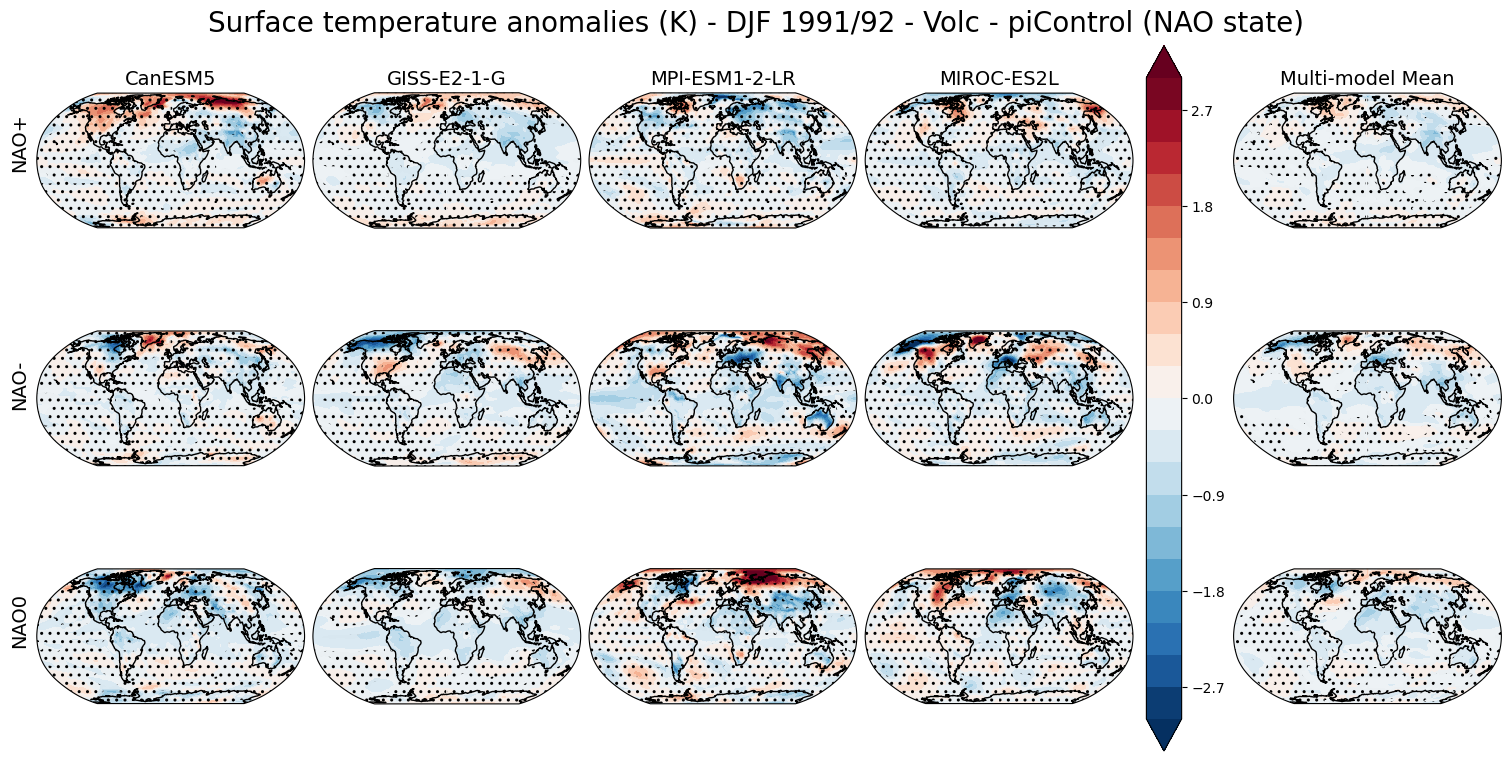

In [ ]:
# all models but only volc - picontrol (NAO+ / NAO-)
fig, axs = plt.subplots(3,5, figsize=(15,7.5), subplot_kw={'projection': ccrs.Robinson()}, layout='constrained')
levels = np.linspace(-3,3,21)

for i, model in enumerate(models):
    picontrolp = dict_picontrolp[model]
    picontroln = dict_picontroln[model]
    picontrolneu = dict_picontrolneu[model]

    volcp = dict_volcp[model]
    volcn = dict_volcn[model]
    volcneu = dict_volcneu[model]
    
    # VOLC (NAO+) - PiControl (NAO+)
    cdata, clon, clat = cutil.add_cyclic((volcp.tas.mean('ens') - picontrolp.mean('time').tas), volcp.lon, volcp.lat)
    c = axs[0,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signp = np.array(stats.ttest_ind(volcp.tas.values, picontrolp.tas.values, axis=0, equal_var=False))[1,...]
    signp = np.nan_to_num(signp, nan=0.99)
    axs[0,i].contourf(volcp.lon, volcp.lat, signp,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    # VOLC (NAO-) - PiControl (NAO-)
    cdata, clon, clat = cutil.add_cyclic((volcn.tas.mean('ens') - picontroln.mean('time').tas), volcn.lon, volcn.lat)
    axs[1,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signn = np.array(stats.ttest_ind(volcn.tas.values, picontroln.tas.values, axis=0, equal_var=False))[1,...]
    signn = np.nan_to_num(signn, nan=0.99)
    axs[1,i].contourf(volcn.lon, volcn.lat, signn,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())
    
    # VOLC (NAO0) - PiControl (NAO0)
    cdata, clon, clat = cutil.add_cyclic((volcneu.tas.mean('ens') - picontrolneu.mean('time').tas), volcneu.lon, volcneu.lat)
    axs[2,i].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

    signneu = np.array(stats.ttest_ind(volcneu.tas.values, picontrolneu.tas.values, axis=0, equal_var=False))[1,...]
    signneu = np.nan_to_num(signneu, nan=0.99)
    axs[2,i].contourf(volcneu.lon, volcneu.lat, signneu,[0.05,1], cmap=plt.get_cmap("gray"), hatches=['..',None], alpha=0.01,
                      transform=ccrs.PlateCarree())

    axs[0,i].set_title(model, fontsize=14)

axs[0,4].set_title('Multi-model Mean', fontsize=14)

cdata, clon, clat = cutil.add_cyclic((meanvolcp.mean('model') - mean_picontrolp.mean('model')), meanvolcp.lon, meanvolcp.lat)
axs[0,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
axs[0,4].contourf(meanvolcp.lon, meanvolcp.lat, get_sign(meanvolcp, mean_picontrolp), [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree())

cdata, clon, clat = cutil.add_cyclic((meanvolcn.mean('model') - mean_picontroln.mean('model')), meanvolcn.lon, meanvolcn.lat)
axs[1,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())

axs[1,4].contourf(meanvolcn.lon, meanvolcn.lat, get_sign(meanvolcn, mean_picontroln), [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree())

cdata, clon, clat = cutil.add_cyclic((meanvolcneu.mean('model') - mean_picontrolneu.mean('model')), meanvolcneu.lon, meanvolcneu.lat)
axs[2,4].contourf(clon, clat, cdata, cmap='RdBu_r', levels=levels, extend='both', transform=ccrs.PlateCarree())
lon, lat = np.meshgrid(meanvolcneu.lon, meanvolcneu.lat)
axs[2,4].contourf(lon, lat, get_sign(meanvolcneu, mean_picontrolneu) , [0,sign], cmap=plt.get_cmap("gray"), hatches=['..', None], alpha=0.01,
                    transform=ccrs.PlateCarree(), transform_first=True)

for ax in axs.flatten():
    ax.coastlines()

axs[0,0].text(-0.1, 0.45, 'NAO+', transform=axs[0,0].transAxes, rotation=90, fontsize=14)
axs[1,0].text(-0.1, 0.45, 'NAO-', transform=axs[1,0].transAxes, rotation=90, fontsize=14)
axs[2,0].text(-0.1, 0.45, 'NAO0', transform=axs[2,0].transAxes, rotation=90, fontsize=14)

plt.colorbar(c, ax=axs[0:3,3])
plt.suptitle('Surface temperature anomalies (K) - DJF 1991/92 - Volc - piControl (NAO state)', fontsize=20)
plt.savefig(plotdir + 'supp5.png', dpi=200)